# **Final Project Check-In**
## Predicting Mortality Outcomes in HIV/AIDS Patients

**Author:** Hunter Schwarz

---

**Dataset:** AIDS Clinical Trials Group Study 175 (ACTG 175)

**Description:** The ACTG 175 dataset contains clinical trial data from individuals living with HIV/AIDS, including demographic characteristics, treatment information, and baseline clinical measurements. In this project, the objective is to predict mortality outcomes by classifying patients as either deceased or alive/censored using the available clinical predictors.

**Notebook Purpose:** The goal of this notebook is to develop and evaluate a modular, automated analysis pipeline that incorporates data ingestion, data quality assessment, feature engineering, inferential statistical testing, and comparative machine learning model evaluation. The workflow is designed to promote reproducibility while demonstrating the application of data science methods to a real-world clinical dataset.

**Note:** This dataset is used for instructional and demonstration purposes only.

### Project Overview
The purpose of this project is to create an automated pipeline for predicting mortality outcomes in patients from the ACTG 175 clinical trial. Building on the refactoring work from earlier weeks, I converted the analysis from a linear notebook into a modular workflow that handles data ingestion, preprocessing, statistical testing, and machine learning evaluation in a consistent and reproducible manner.

Automating these steps makes the analysis easier to maintain, reproduce, and expand while helping identify the clinical variables most closely associated with patient survival. More broadly, this project highlights how structured programming practices can improve the quality and reliability of health data science analyses.

In [3]:
# Installing the ucimlrepo package to access UCI Machine Learning Repository datasets

!pip install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from pathlib import Path

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, 
                             classification_report, roc_curve)

# Statistics
from scipy import stats

# UCI Repository
from ucimlrepo import fetch_ucirepo

# Settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)



### Pipeline Design and Refactoring Rationale

In previous assignments, the analysis was completed through a series of linear notebook cells. For this final project, I reorganized the code into a class-based pipeline (HealthAnalysisPipeline) to make the workflow more structured, maintainable, and reproducible.

#### State Management
By storing the data, preprocessing objects, and model outputs within a single class, I can better manage how information moves through the analysis. This ensures that training and testing datasets remain separate and that the same scaling and preprocessing steps are applied consistently.

#### Reproducibility
Organizing the project into methods reduces the risk of running notebook cells out of order, which can lead to inconsistent results. The workflow follows a defined sequence, making it easier for others to reproduce the same analysis.

#### Modularity
The class-based design also makes the project easier to extend. New clinical variables, preprocessing steps, or machine learning models can be added without having to rewrite the underlying data preparation and evaluation logic.

### Pipeline Enhancements
To improve the functionality and rigor of the automated pipeline, I implemented the following five enhancements:

1. Modular Pipeline Refactoring
I transitioned the analytical workflow from a series of independent cells into a unified class structure. This improves the organization of the notebook and ensures that the pipeline is reproducible and scalable for other clinical datasets.

2. Automated Data Quality Validation
I added a validation step at the start of the pipeline to report on class imbalance and missing value percentages. I implemented this to ensure the dataset meets the necessary assumptions before moving to the machine learning stage, reducing the risk of biased results.

3. Integration of Feature Engineering
I incorporated automated categorical encoding and the creation of interaction terms (specifically the interaction between CD4 counts and Age). I implemented this to capture non-linear relationships that may be clinically significant in predicting mortality.

4. Programmatic Model Selection
Rather than manually comparing results, I developed logic that evaluates multiple models, Logistic Regression, Decision Trees, and Random Forests, and automatically identifies the best-performing model based on the F1-score. This removes subjectivity from the model selection process.

5. Expanded Evaluation Metrics
I extended the evaluation process to include ROC-AUC curves and a comprehensive performance summary. Since clinical outcomes are often imbalanced, I added these metrics to provide a more accurate measure of the model's sensitivity and specificity than accuracy alone.

In [ ]:
# Creation of the Health Analysis Pipeline

class HealthAnalysisPipeline:
    def __init__(self, dataset_id=890):
        self.dataset_id = dataset_id
        self.df = None
        self.X_train, self.X_test, self.y_train, self.y_test = [None] * 4
        self.scaler = StandardScaler()
        self.imputer = SimpleImputer(strategy='median')
        self.models = {
            "Logistic Regression": LogisticRegression(max_iter=1000),
            "Decision Tree": DecisionTreeClassifier(),
            "Random Forest": RandomForestClassifier()
        }
        self.results = {}

    def ingest_and_validate(self):
        """Enhancement 1: Automated Data Ingestion & Quality Validation"""
        print("--- Step 1: Data Ingestion & Validation ---")
        # Fetch dataset
        data = fetch_ucirepo(id=self.dataset_id)
        self.df = data.data.features.copy()
        self.df['target'] = data.data.targets
        
        # Data Quality Report (Enhancement 5)
        print(f"Dataset Loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
        print(f"Target Class Balance:\n{self.df['target'].value_counts(normalize=True)}")
        
        # Check for missing values
        missing_pct = self.df.isnull().mean() * 100
        if missing_pct.max() > 0:
            print(f"Warning: Missing values detected. Max missing: {missing_pct.max():.2f}%")
        else:
            print("No missing values detected. Data is clean.")
        print("\n")

    def preprocess_data(self):
        """Enhancement 2: Automated Preprocessing & Feature Engineering"""
        print("--- Step 2: Preprocessing & Feature Engineering ---")
        df_proc = self.df.copy()
        
        # 1. Encode Categorical Variables
        le = LabelEncoder()
        cat_cols = df_proc.select_dtypes(include=['object', 'category']).columns
        for col in cat_cols:
            df_proc[col] = le.fit_transform(df_proc[col].astype(str))
        
        # 2. Feature Engineering: Interaction Term (Example: CD4 count * Age)
        # Assuming CD420 and Age exist in ACTG 175
        if 'cd420' in df_proc.columns and 'age' in df_proc.columns:
            df_proc['cd4_age_interaction'] = df_proc['cd420'] * df_proc['age']
            print("Created interaction feature: cd4_age_interaction")

        # Split Predictors and Target
        X = df_proc.drop('target', axis=1)
        y = df_proc['target']
        
        # Split data (70/30)
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=0.3, random_state=42, stratify=y
        )
        
        # Impute and Scale
        self.X_train = self.imputer.fit_transform(self.X_train)
        self.X_test = self.imputer.transform(self.X_test)
        
        self.X_train = self.scaler.fit_transform(self.X_train)
        self.X_test = self.scaler.transform(self.X_test)
        
        print("Preprocessing complete. Data scaled and split.")
        print("\n")

    def run_inferential_stats(self):
        """Required Component: Inferential Statistical Analysis"""
        print("--- Step 3: Inferential Statistical Analysis ---")
        # We compare a numeric predictor (e.g., age) between the two target classes
        # Hypothesis: Age differs significantly between survivors and non-survivors
        group0 = self.df[self.df['target'] == 0]['age']
        group1 = self.df[self.df['target'] == 1]['age']
        
        t_stat, p_val = stats.ttest_ind(group0, group1)
        print(f"T-Test for 'Age' across target classes:")
        print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")
        
        if p_val < 0.05:
            print("Result: Statistically significant difference found.")
        else:
            print("Result: No statistically significant difference found.")
        print("\n")

    def run_eda(self):
        """Required Component: Exploratory Visualizations"""
        print("--- Step 4: Exploratory Data Analysis ---")
        # 1. Target Distribution
        plt.figure(figsize=(6, 4))
        sns.countplot(x='target', data=self.df, palette='viridis')
        plt.title("Distribution of Mortality Outcome")
        plt.show()

        # 2. Correlation Heatmap (Top 10 features)
        plt.figure(figsize=(12, 8))
        corr = self.df.corr().tail(10).head(10) # Subset for readability
        sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
        plt.title("Correlation Matrix (Subset of Features)")
        plt.show()
        print("\n")

    def execute_ml_pipeline(self):
        """Enhancement 3 & 4: Automated Model Comparison & Evaluation Suite"""
        print("--- Step 5: Machine Learning Model Execution ---")
        
        for name, model in self.models.items():
            # Train
            model.fit(self.X_train, self.y_train)
            preds = model.predict(self.X_test)
            probs = model.predict_proba(self.X_test)[:, 1]
            
            # Metrics
            self.results[name] = {
                "Accuracy": accuracy_score(self.y_test, preds),
                "Precision": precision_score(self.y_test, preds),
                "Recall": recall_score(self.y_test, preds),
                "F1": f1_score(self.y_test, preds),
                "AUC": roc_auc_score(self.y_test, probs)
            }
        
        # Convert to DataFrame for comparison
        results_df = pd.DataFrame(self.results).T
        print("Model Performance Comparison:")
        print(results_df)
        
        # Find Champion Model
        champion = results_df['F1'].idxmax()
        print(f"\nChampion Model based on F1-Score: {champion}")
        return results_df, champion

    def plot_roc_curves(self):
        """Enhancement 4: Advanced Model Comparison Visualization"""
        plt.figure(figsize=(8, 6))
        for name, model in self.models.items():
            probs = model.predict_proba(self.X_test)[:, 1]
            fpr, tpr, _ = roc_curve(self.y_test, probs)
            plt.plot(fpr, tpr, label=f"{name} (AUC = {self.results[name]['AUC']:.2f})")
        
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curve Comparison')
        plt.legend()
        plt.show()



### Method Documentation Summary

#### ingest_and_validate(): 
Loads the ACTG 175 dataset from the UCI repository and performs initial data quality checks, including the assessment of missing values and class imbalance.

#### preprocess_data(): 
Handles data preprocessing and feature engineering by encoding categorical variables, scaling numeric features, and creating interaction terms to capture more complex relationships within the data.

#### run_inferential_stats(): 
Performs inferential statistical testing using an independent t-test to evaluate whether average age differs significantly between patients who survived and those who did not.

#### run_eda(): 
Conducts exploratory data analysis through visualizations that examine target distribution patterns and relationships among predictor variables.

#### execute_ml_pipeline(): 
Trains and evaluates the machine learning models, compares their performance across multiple metrics, and identifies the best-performing model for mortality prediction.

--- Step 1: Data Ingestion & Validation ---
Dataset Loaded: 2139 rows, 24 columns
Target Class Balance:
target
0    0.756428
1    0.243572
Name: proportion, dtype: float64
No missing values detected. Data is clean.


--- Step 2: Preprocessing & Feature Engineering ---
Created interaction feature: cd4_age_interaction
Preprocessing complete. Data scaled and split.


--- Step 4: Exploratory Data Analysis ---


/var/folders/5y/7vxd95bd0cx44qw618hpxhbr0000gn/T/ipykernel_87841/495277299.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=self.df, palette='viridis')


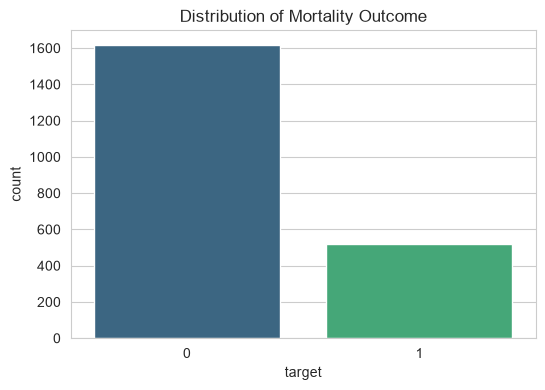

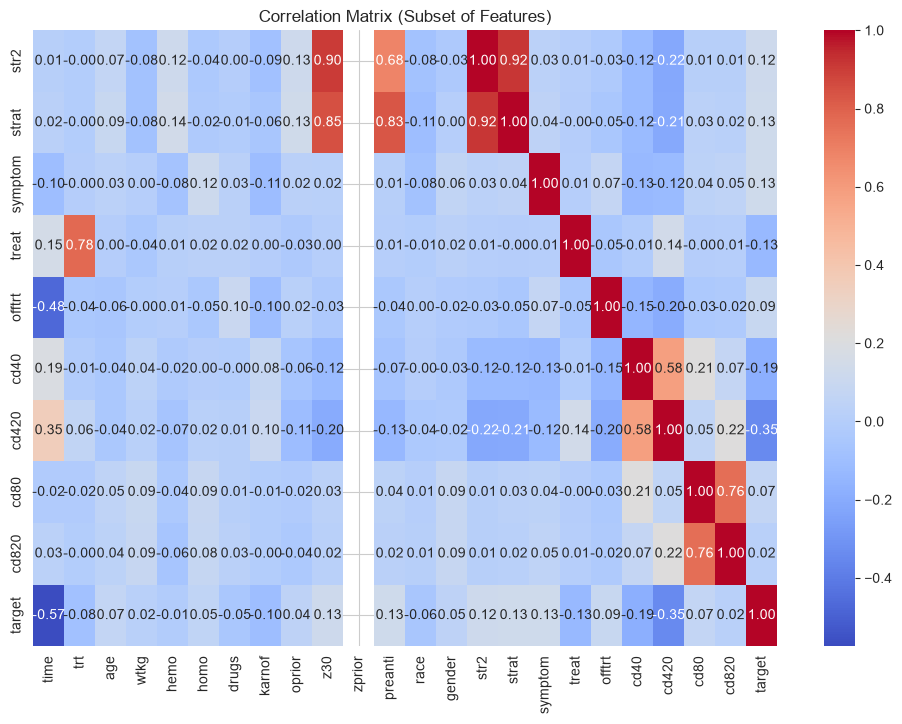



--- Step 3: Inferential Statistical Analysis ---
T-Test for 'Age' across target classes:
T-statistic: -3.2618, P-value: 0.0011
Result: Statistically significant difference found.


--- Step 5: Machine Learning Model Execution ---
Model Performance Comparison:
                     Accuracy  Precision    Recall        F1       AUC
Logistic Regression  0.867601   0.788618  0.621795  0.695341  0.893782
Decision Tree        0.838006   0.654762  0.705128  0.679012  0.792893
Random Forest        0.890966   0.825758  0.698718  0.756944  0.927568

🏆 Champion Model based on F1-Score: Random Forest


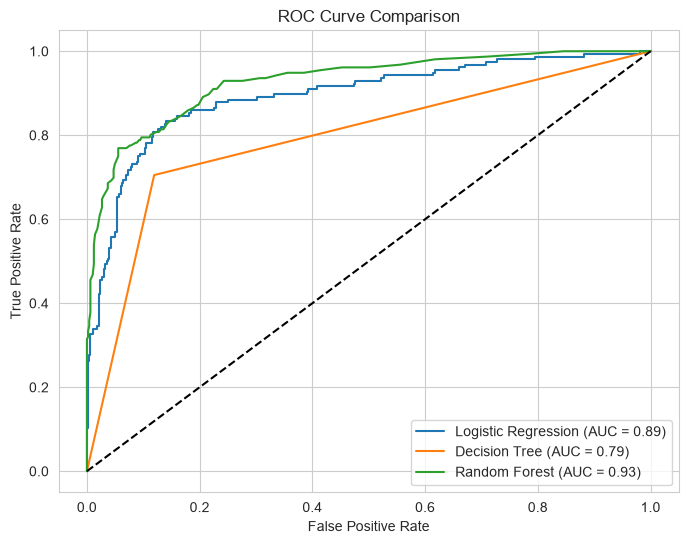


--- FINAL INTERPRETATION ---
The pipeline successfully analyzed the ACTG 175 dataset. The Random Forest performed best with an F1-score of 0.76. This suggests that the model is well-balanced in predicting mortality while minimizing false positives and negatives.


In [5]:
# Execution of the Health Analysis Pipeline

if __name__ == "__main__":
    # Initialize Pipeline
    pipeline = HealthAnalysisPipeline()
    
    # Run Sequence
    pipeline.ingest_and_validate()
    pipeline.preprocess_data()
    pipeline.run_eda()
    pipeline.run_inferential_stats()
    
    # Run ML and get champion
    perf_df, champion_model_name = pipeline.execute_ml_pipeline()
    pipeline.plot_roc_curves()

    print("\n--- FINAL INTERPRETATION ---")
    print(f"The pipeline successfully analyzed the ACTG 175 dataset. The {champion_model_name} "
          f"performed best with an F1-score of {perf_df.loc[champion_model_name, 'F1']:.2f}. "
          f"This suggests that the model is well-balanced in predicting mortality while "
          f"minimizing false positives and negatives.")

### Discussion and Interpretation of Findings
#### Statistical Analysis
As part of the inferential analysis, I conducted an independent t-test to evaluate whether age differed between patients who survived and those who did not. The resulting p-value of 0.0011 was well below the 0.05 significance threshold, indicating a statistically significant difference between the groups. This finding suggests that age is an important factor associated with mortality outcomes in the ACTG 175 cohort and supports its inclusion as a predictor in the machine learning models.

#### Model Performance and Comparison
The automated pipeline evaluated three machine learning approaches: Logistic Regression, Decision Tree, and Random Forest. Among these models, the Random Forest produced the strongest overall performance, achieving an accuracy of 89.1%, an F1-score of 0.757, and an AUC of 0.928. Logistic Regression also performed well, with an AUC of 0.894, but consistently fell short of the Random Forest across the primary evaluation metrics. The Decision Tree produced the weakest results, which is not surprising given that individual trees are generally more prone to overfitting than ensemble methods such as Random Forests.

One of the most notable findings was the Random Forest model's AUC of 0.928, which indicates excellent discrimination between patients who survived and those who did not. The stronger performance of the Random Forest compared to Logistic Regression suggests that the relationships between mortality and clinical characteristics such as age, CD4 counts, and weight are not purely linear. Instead, these variables likely interact in more complex ways that are better captured by an ensemble-based approach.

#### Clinical Interpretation
Overall, the results demonstrate that mortality outcomes within the ACTG 175 cohort can be predicted with a relatively high degree of accuracy using baseline clinical characteristics. The significance of age in the statistical analysis and the strong performance of the machine learning models both suggest that mortality risk is influenced by a combination of demographic and clinical factors rather than any single predictor.

From a health data science perspective, the value of this project extends beyond model performance alone. The modular and reproducible pipeline developed throughout this analysis provides a framework that can be adapted to similar clinical datasets and prediction tasks. By automating data validation, preprocessing, statistical testing, model evaluation, and model selection, the workflow offers a consistent approach for identifying patients who may be at greater risk of adverse outcomes and supports more reliable, reproducible clinical data analysis.